# Libraries

In [70]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from textblob import TextBlob

import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report,
    f1_score
)

from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import OrdinalEncoder
from transformers import AutoTokenizer
from transformers import AutoModelForSequenceClassification, TrainingArguments, Trainer
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
import joblib

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report
import matplotlib.pyplot as plt
from scipy.stats import f_oneway

# Data Preprocessing

In [71]:
df_math = pd.read_csv('/content/student-mat.csv', sep=';')
df_port = pd.read_csv('/content/student-por.csv', sep=';')

# Define the CORRECT column names to fix typos in the original data
corrected_column_names = [
    'school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu',
    'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures',
    'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet',
    'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health','absences',
    'G1', 'G2', 'G3'
]

df_math.columns = corrected_column_names
df_port.columns = corrected_column_names


In [72]:
df_math

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
390,MS,M,20,U,LE3,A,2,2,services,services,...,5,5,4,4,5,4,11,9,9,9
391,MS,M,17,U,LE3,T,3,1,services,services,...,2,4,5,3,4,2,3,14,16,16
392,MS,M,21,R,GT3,T,1,1,other,other,...,5,5,3,3,3,3,3,10,8,7
393,MS,M,18,R,LE3,T,3,2,services,other,...,4,4,1,3,4,5,0,11,12,10


In [73]:
df_port

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
644,MS,F,19,R,GT3,T,2,3,services,other,...,5,4,2,1,2,5,4,10,11,10
645,MS,F,18,U,LE3,T,3,1,teacher,services,...,4,3,4,1,1,1,4,15,15,16
646,MS,F,18,U,GT3,T,1,1,other,other,...,1,1,1,1,1,5,6,11,12,9
647,MS,M,17,U,LE3,T,3,1,services,services,...,2,4,5,3,4,2,6,10,10,10


In [74]:
# Add a 'subject' column to each DataFrame before combining
df_math['subject'] = 'math'
df_port['subject'] = 'portuguese'

# Combine the two DataFrames by stacking them vertically
df_combined = pd.concat([df_math, df_port], ignore_index=True)

df_combined

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,subject
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,3,4,1,1,3,6,5,6,6,math
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,3,3,1,1,3,4,5,5,6,math
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,3,2,2,3,3,10,7,8,10,math
3,GP,F,15,U,GT3,T,4,2,health,services,...,2,2,1,1,5,2,15,14,15,math
4,GP,F,16,U,GT3,T,3,3,other,other,...,3,2,1,2,5,4,6,10,10,math
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1039,MS,F,19,R,GT3,T,2,3,services,other,...,4,2,1,2,5,4,10,11,10,portuguese
1040,MS,F,18,U,LE3,T,3,1,teacher,services,...,3,4,1,1,1,4,15,15,16,portuguese
1041,MS,F,18,U,GT3,T,1,1,other,other,...,1,1,1,1,5,6,11,12,9,portuguese
1042,MS,M,17,U,LE3,T,3,1,services,services,...,4,5,3,4,2,6,10,10,10,portuguese


In [75]:
df_combined.isnull().sum()

,0
school,0
sex,0
age,0
address,0
famsize,0
Pstatus,0
Medu,0
Fedu,0
Mjob,0
Fjob,0


In [76]:
df_copy = df_combined.copy()

# Dropping irrelevant features

df_copy.drop(columns=['reason', 'nursery', 'Pstatus'] , axis=1, inplace=True)

In [77]:
# Encoding categorical features
cols_to_encode = ['school', 'sex', 'address', 'famsize', 'Mjob', 'Fjob',
                  'guardian', 'schoolsup', 'famsup', 'paid', 'activities',
                  'higher', 'internet', 'romantic', 'subject']

encoder = OrdinalEncoder()

df_copy[cols_to_encode] = encoder.fit_transform(df_combined[cols_to_encode])

df_copy

,school,sex,age,address,famsize,Medu,Fedu,Mjob,Fjob,guardian,...,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,subject
0,0.0,0.0,18,1.0,0.0,4,4,0.0,4.0,1.0,...,3,4,1,1,3,6,5,6,6,0.0
1,0.0,0.0,17,1.0,0.0,1,1,0.0,2.0,0.0,...,3,3,1,1,3,4,5,5,6,0.0
2,0.0,0.0,15,1.0,1.0,1,1,0.0,2.0,1.0,...,3,2,2,3,3,10,7,8,10,0.0
3,0.0,0.0,15,1.0,0.0,4,2,1.0,3.0,1.0,...,2,2,1,1,5,2,15,14,15,0.0
4,0.0,0.0,16,1.0,0.0,3,3,2.0,2.0,0.0,...,3,2,1,2,5,4,6,10,10,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1039,1.0,0.0,19,0.0,0.0,2,3,3.0,2.0,1.0,...,4,2,1,2,5,4,10,11,10,1.0
1040,1.0,0.0,18,1.0,1.0,3,1,4.0,3.0,1.0,...,3,4,1,1,1,4,15,15,16,1.0
1041,1.0,0.0,18,1.0,0.0,1,1,2.0,2.0,1.0,...,1,1,1,1,5,6,11,12,9,1.0
1042,1.0,1.0,17,1.0,1.0,3,1,3.0,3.0,1.0,...,4,5,3,4,2,6,10,10,10,1.0


# Feature Engineering & Splitting

In [78]:
# Adding more features

total_days = 90

df_copy['attendance_ratio'] = 1 - (df_copy['absences'] / total_days)

df_copy['average_grade'] = (df_copy['G1'] + df_copy['G2'] + df_copy['G3']) / 3


In [79]:
bins = [-1, 10, 14, 21]
labels = ['High Risk', 'Medium Risk', 'Low Risk']

df_copy['performance_category'] = pd.cut(df_copy['G3'], bins=bins, labels=labels)

y = df_copy['performance_category']

X = df_copy.drop(columns=['G3', 'performance_category'])


# Split the data. 'stratify=y' ensures each risk category is proportionally represented in both sets.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Shape of X_train:", X_train.shape)
print("Shape of X_test:", X_test.shape)
print("Shape of y_train:", y_train.shape)
print("Shape of y_test:", y_test.shape)

# Show the first few rows of the prepared features (X_train)
print("\nFeatures (X) preview:")
print(X_train.head())

# Show the distribution of the target variable in both sets
print("\nTarget distribution in y_train:")
print(y_train.value_counts())
print("\nTarget distribution in y_test:")
print(y_test.value_counts())

Shape of X_train: (835, 32)
Shape of X_test: (209, 32)
Shape of y_train: (835,)
Shape of y_test: (209,)

Features (X) preview:
     school  sex  age  address  famsize  Medu  Fedu  Mjob  Fjob  guardian  \
968     1.0  0.0   17      1.0      0.0     1     1   2.0   0.0       1.0   
887     1.0  0.0   16      0.0      0.0     2     2   1.0   2.0       1.0   
511     0.0  1.0   15      1.0      0.0     4     4   2.0   4.0       0.0   
174     0.0  0.0   16      1.0      1.0     3     3   2.0   2.0       1.0   
32      0.0  1.0   15      0.0      0.0     4     3   4.0   0.0       1.0   

     ...  goout  Dalc  Walc  health  absences  G1  G2  subject  \
968  ...      2     1     2       5         9   7   9      1.0   
887  ...      2     1     1       3         2   8  10      1.0   
511  ...      3     1     1       2         4  16  15      1.0   
174  ...      5     1     1       4         4  10  11      0.0   
32   ...      2     1     1       5         0  17  16      0.0   

     attendan

# Mathematics for ML

In [80]:
# Normalization

# We use .select_dtypes to find all number-based columns (int64 and float64)
numeric_columns = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()

scaler = MinMaxScaler()

X_train_scaled = X_train.copy()
X_train_scaled[numeric_columns] = scaler.fit_transform(X_train[numeric_columns])

X_test_scaled = X_test.copy()
X_test_scaled[numeric_columns] = scaler.transform(X_test[numeric_columns])


print("\nFirst 5 rows of the scaled TRAINING features:")
print(X_train_scaled[numeric_columns].head())
print(f"\nMin values in training set:\n{X_train_scaled[numeric_columns].min()}")
print(f"\nMax values in training set:\n{X_train_scaled[numeric_columns].max()}")


First 5 rows of the scaled TRAINING features:
     school  sex       age  address  famsize  Medu  Fedu  Mjob  Fjob  \
968     1.0  0.0  0.285714      1.0      0.0  0.25  0.25  0.50   0.0   
887     1.0  0.0  0.142857      0.0      0.0  0.50  0.50  0.25   0.5   
511     0.0  1.0  0.000000      1.0      0.0  1.00  1.00  0.50   1.0   
174     0.0  0.0  0.142857      1.0      1.0  0.75  0.75  0.50   0.5   
32      0.0  1.0  0.000000      0.0      0.0  1.00  0.75  1.00   0.0   

     guardian  ...  goout  Dalc  Walc  health  absences        G1        G2  \
968       0.5  ...   0.25   0.0  0.25    1.00  0.160714  0.368421  0.473684   
887       0.5  ...   0.25   0.0  0.00    0.50  0.035714  0.421053  0.526316   
511       0.0  ...   0.50   0.0  0.00    0.25  0.071429  0.842105  0.789474   
174       0.5  ...   1.00   0.0  0.00    0.75  0.071429  0.526316  0.578947   
32        0.5  ...   0.25   0.0  0.00    1.00  0.000000  0.894737  0.842105   

     subject  attendance_ratio  average_grade

# Algorithms & Models

In [81]:
models = {
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'Support Vector Machine': SVC(random_state=42)
}

results_list = []

for model_name, model in models.items():
    print(f"Training {model_name}...")

    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_test_scaled)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average='weighted')
    recall = recall_score(y_test, y_pred, average='weighted')
    f1 = f1_score(y_test, y_pred, average='weighted')

    results_list.append({
        'Model': model_name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1
    })

    print(f"\n{model_name} Classification Report:")
    print(classification_report(y_test, y_pred))
    print("=" * 60 + "\n")

# Convert the list of results to a DataFrame
results_df = pd.DataFrame(results_list)

# Display the results comparison
print("Model Performance Comparison:")
print(results_df.to_string(index=False))

# Find the best model based on F1-Score
best_model_name = results_df.loc[results_df['F1-Score'].idxmax(), 'Model']
best_model = models[best_model_name]
print(f"\nBest performing model: {best_model_name}")

joblib.dump(best_model, 'student_model.pkl')
print("Best model saved as 'student_model.pkl'")

Training Logistic Regression...

Logistic Regression Classification Report:
              precision    recall  f1-score   support

   High Risk       0.90      0.81      0.85        77
    Low Risk       0.84      0.76      0.79        41
 Medium Risk       0.76      0.86      0.80        91

    accuracy                           0.82       209
   macro avg       0.83      0.81      0.82       209
weighted avg       0.83      0.82      0.82       209


Training Decision Tree...

Decision Tree Classification Report:
              precision    recall  f1-score   support

   High Risk       0.90      0.91      0.90        77
    Low Risk       0.97      0.88      0.92        41
 Medium Risk       0.87      0.90      0.89        91

    accuracy                           0.90       209
   macro avg       0.91      0.90      0.90       209
weighted avg       0.90      0.90      0.90       209


Training Random Forest...

Random Forest Classification Report:
              precision    recal

# Deep Learning & NLP

Number of features: 32
Number of classes: 3


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,291 (16.76 KB)

 Trainable params: 4,291 (16.76 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.3923 - loss: 1.1047 - val_accuracy: 0.4593 - val_loss: 1.0374
Epoch 2/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4583 - loss: 1.0436 - val_accuracy: 0.5311 - val_loss: 0.9895
Epoch 3/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5224 - loss: 0.9954 - val_accuracy: 0.5646 - val_loss: 0.9333
Epoch 4/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5420 - loss: 0.9554 - val_accuracy: 0.6124 - val_loss: 0.8762
Epoch 5/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5827 - loss: 0.8877 - val_accuracy: 0.6411 - val_loss: 0.8104
Epoch 6/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6029 - loss: 0.8359 - val_accuracy: 0.6699 - val_loss: 0.7673
Epoch 7/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6088 - loss: 0.8117 - val_accuracy: 0.7081 - val_loss: 0.7248
Epoch 8/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6327 - loss: 0.7540 - val_accuracy: 0.7033 - val_loss

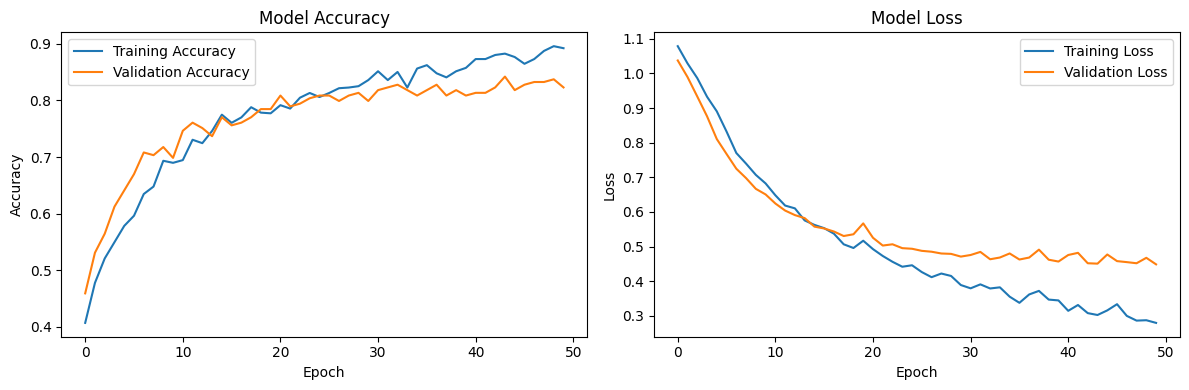

Neural network model saved as 'student_performance_nn_model.h5'


In [82]:
# Neural networks typically need numerical labels
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

# Get the number of features and classes
num_features = X_train_scaled.shape[1]
num_classes = len(np.unique(y_train_encoded))

print(f"Number of features: {num_features}")
print(f"Number of classes: {num_classes}")

# Build the neural network model
model = keras.Sequential([
    layers.Dense(64, activation='relu', input_shape=(num_features,)),
    layers.Dropout(0.2),
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(num_classes, activation='softmax')
])

# Compile the model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Display the model architecture
model.summary()

# Train the model
history = model.fit(
    X_train_scaled, y_train_encoded,
    epochs=50,
    batch_size=32,
    validation_data=(X_test_scaled, y_test_encoded),
    verbose=1
)

# Evaluate the model on test data
test_loss, test_accuracy = model.evaluate(X_test_scaled, y_test_encoded, verbose=0)
print(f"\nTest accuracy: {test_accuracy:.4f}")

# Make predictions
y_pred_proba = model.predict(X_test_scaled)
y_pred = np.argmax(y_pred_proba, axis=1)

# Convert back to original labels
y_pred_labels = label_encoder.inverse_transform(y_pred)

# Calculate additional metrics

print("\nNeural Network Classification Report:")
print(classification_report(y_test, y_pred_labels))

# Plot training history (optional but useful for understanding model behavior)


plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

# Save the trained model
model.save('student_performance_nn_model.h5')
print("Neural network model saved as 'student_performance_nn_model.h5'")

Sample of feedback and sentiment scores:
  performance_category                                           feedback  \
0            High Risk     I'm passing the class but not excelling in it.   
1            High Risk     I'm passing the class but not excelling in it.   
2            High Risk     I'm passing the class but not excelling in it.   
3             Low Risk  The assignments are interesting and help reinf...   
4            High Risk     I'm passing the class but not excelling in it.   
5             Low Risk  The assignments are interesting and help reinf...   
6          Medium Risk  The course meets my expectations for a college...   
7            High Risk     I'm passing the class but not excelling in it.   
8             Low Risk  The assignments are interesting and help reinf...   
9             Low Risk  The assignments are interesting and help reinf...   

   sentiment_score sentiment_category  
0              0.0            Neutral  
1              0.0            N

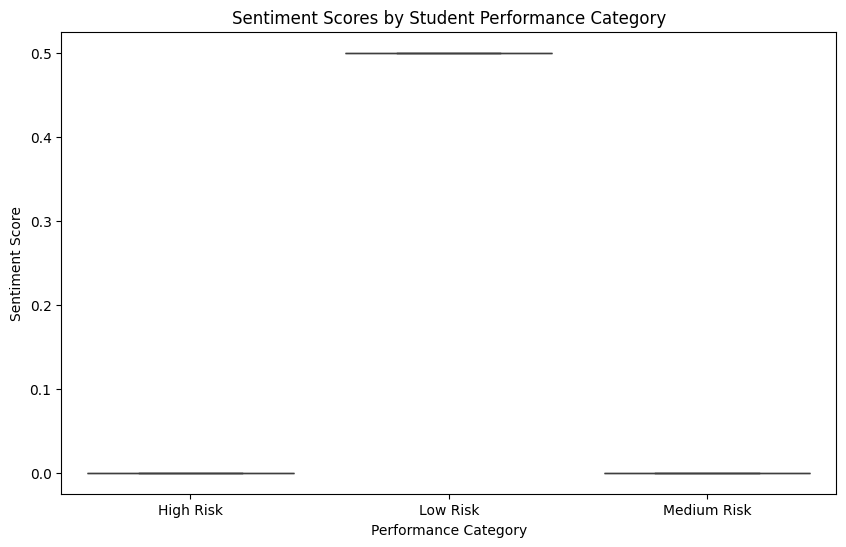


Cross-tabulation of sentiment vs performance (row percentages):
sentiment_category    Neutral  Positive
performance_category                   
High Risk                 1.0       0.0
Low Risk                  0.0       1.0
Medium Risk               1.0       0.0

ANOVA test results: F-statistic = inf, p-value = 0.0000
The relationship between sentiment and performance is statistically significant.

Dataset with sentiment analysis saved as 'student_data_with_sentiment.csv'


/usr/local/lib/python3.12/dist-packages/scipy/stats/_axis_nan_policy.py:579: ConstantInputWarning: Each of the input arrays is constant; the F statistic is not defined or infinite
  res = hypotest_fun_out(*samples, **kwds)


In [83]:
# Set random seed for reproducibility
np.random.seed(42)

# Create sample feedback comments that might correlate with performance
positive_comments = [
    "I really enjoy this class and find the material fascinating.",
    "The teacher explains concepts clearly and is always available for help.",
    "I'm understanding the material well and keeping up with assignments.",
    "This is my favorite subject and I look forward to every class.",
    "The coursework is challenging but fair, and I'm learning a lot.",
    "I feel supported by my teacher and classmates in this course.",
    "The assignments are interesting and help reinforce the concepts.",
    "I'm confident about my progress in this class.",
    "The teacher provides helpful feedback on my work.",
    "I'm motivated to study and do well in this subject."
]

negative_comments = [
    "I'm struggling to understand the material and falling behind.",
    "The teacher doesn't explain things clearly and I'm often confused.",
    "I find the assignments too difficult and don't know where to get help.",
    "I'm losing interest in this subject and thinking about dropping.",
    "The pace is too fast and I can't keep up with the workload.",
    "I don't feel supported by the teacher or the institution.",
    "The grading seems unfair and doesn't reflect my effort.",
    "I'm experiencing a lot of stress and anxiety about this class.",
    "The material is boring and not engaging at all.",
    "I'm considering switching to a different program or school."
]

neutral_comments = [
    "The class is okay, nothing special but not terrible either.",
    "I'm doing fine in the class, keeping up with assignments.",
    "The teacher is decent and the material is manageable.",
    "I attend class regularly and complete my work on time.",
    "It's a standard course with standard expectations.",
    "I don't have strong feelings about this class one way or another.",
    "The course meets my expectations for a college-level class.",
    "I'm passing the class but not excelling in it.",
    "The workload is reasonable and the material is moderately interesting.",
    "This class is neither my favorite nor my least favorite."
]

# Create a function to generate feedback based on performance category
def generate_feedback(performance_category):
    if performance_category == 'Low Risk':
        # Mostly positive comments for low-risk students
        weights = [0.6, 0.2, 0.2]
    elif performance_category == 'Medium Risk':
        # Mixed comments for medium-risk students
        weights = [0.3, 0.4, 0.3]
    else:
        # Mostly negative comments for high-risk students
        weights = [0.2, 0.2, 0.6]

    # Randomly select a comment based on weights
    comment_type = np.random.choice(['positive', 'neutral', 'negative'], p=weights)

    if comment_type == 'positive':
        return np.random.choice(positive_comments)
    elif comment_type == 'neutral':
        return np.random.choice(neutral_comments)
    else:
        return np.random.choice(negative_comments)

# Add feedback to our main DataFrame
df_copy['feedback'] = df_copy['performance_category'].apply(generate_feedback)

# Perform sentiment analysis on the feedback
def analyze_sentiment(text):
    analysis = TextBlob(text)
    return analysis.sentiment.polarity  # Returns a value between -1 (negative) and 1 (positive)

df_copy['sentiment_score'] = df_copy['feedback'].apply(analyze_sentiment)

# Categorize sentiment for easier analysis
def categorize_sentiment(score):
    if score > 0.1:
        return 'Positive'
    elif score < -0.1:
        return 'Negative'
    else:
        return 'Neutral'

df_copy['sentiment_category'] = df_copy['sentiment_score'].apply(categorize_sentiment)

# Display the results
print("Sample of feedback and sentiment scores:")
print(df_copy[['performance_category', 'feedback', 'sentiment_score', 'sentiment_category']].head(10))

# Analyze correlation between sentiment and performance
# Convert 'performance_category' to object type for aggregation
df_copy['performance_category'] = df_copy['performance_category'].astype('object')
sentiment_by_performance = df_copy.groupby('performance_category')['sentiment_score'].mean()
print("\nAverage sentiment score by performance category:")
print(sentiment_by_performance)

# Visualize the relationship
plt.figure(figsize=(10, 6))
sns.boxplot(x='performance_category', y='sentiment_score', data=df_copy)
plt.title('Sentiment Scores by Student Performance Category')
plt.xlabel('Performance Category')
plt.ylabel('Sentiment Score')
plt.show()

# Create a cross-tabulation of sentiment vs performance
cross_tab = pd.crosstab(df_copy['performance_category'], df_copy['sentiment_category'], normalize='index')
print("\nCross-tabulation of sentiment vs performance (row percentages):")
print(cross_tab)

# Statistical test to see if the relationship is significant
from scipy.stats import f_oneway

# Perform ANOVA test
low_risk_sentiment = df_copy[df_copy['performance_category'] == 'Low Risk']['sentiment_score']
medium_risk_sentiment = df_copy[df_copy['performance_category'] == 'Medium Risk']['sentiment_score']
high_risk_sentiment = df_copy[df_copy['performance_category'] == 'High Risk']['sentiment_score']

f_stat, p_value = f_oneway(low_risk_sentiment, medium_risk_sentiment, high_risk_sentiment)
print(f"\nANOVA test results: F-statistic = {f_stat:.4f}, p-value = {p_value:.4f}")

if p_value < 0.05:
    print("The relationship between sentiment and performance is statistically significant.")
else:
    print("The relationship between sentiment and performance is not statistically significant.")

# Save the enhanced dataset with feedback and sentiment
df_copy.to_csv('student_data_with_sentiment.csv', index=False)
print("\nDataset with sentiment analysis saved as 'student_data_with_sentiment.csv'")

In [85]:
from google.colab import files
import joblib

joblib.dump(encoder, 'encoder.pkl')
joblib.dump(scaler, 'scaler.pkl')
files.download('encoder.pkl')
files.download('scaler.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>